In [34]:
import pandas,json,numpy
from matplotlib import pyplot

In [35]:
# Import the data
model_json = json.load(open("./data/output/invert_organic_posterior_results_with_burial.json"))

time = model_json[0]["time"]
time_step_length = numpy.abs(numpy.diff(numpy.array(time)*model_json[0]["time_multiplier"]))

total_excess_organic_burial = [model["total_excess_organic_burial"] for model in model_json]

organic_carbon_burial = [model["organic_burial"] for model in model_json]
organic_carbon_burial_per_year = [organic_burial/time_step_length for organic_burial in organic_carbon_burial]

excess_organic_carbon_burial = [model["excess_organic_burial"] for model in model_json]
excess_organic_burial_per_year = [organic_burial/time_step_length for organic_burial in excess_organic_carbon_burial]


Text(0, 0.5, 'Density')

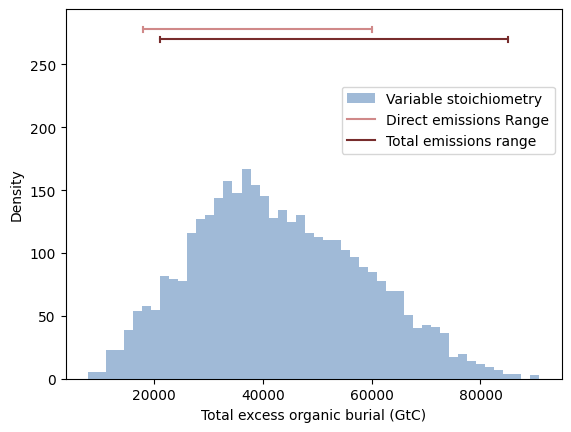

In [36]:
figure,axes = pyplot.subplots(1,1)
# handle_0 = axes.hist(total_excess_organic_burial_constant,color="#6cb7c4",zorder=2,bins=50,alpha=0.5)
handle_1 = axes.hist(total_excess_organic_burial,color="#4276b1",zorder=3,bins=50,alpha=0.5)
# handle_test = axes.hist(total_excess_organic_burial_test,color="#ff0000",zorder=1,bins=50,alpha=0.5)

handle_emissions = axes.plot([18000,60000],[278,278],color="#d08989",zorder=1)
axes.plot([18000,18000],[276,280],color="#d08989",zorder=1)
axes.plot([60000,60000],[276,280],color="#d08989",zorder=1)

handle_total_emissions = axes.plot([18000+3000,60000+15000+10000],[270,270],color="#772c2c",zorder=1)
axes.plot([18000+3000,18000+3000],[268,272],color="#772c2c",zorder=1)
axes.plot([60000+15000+10000,60000+15000+10000],[268,272],color="#772c2c",zorder=1)

axes.legend((handle_1[2],handle_emissions[0],handle_total_emissions[0]),#type: ignore
            ["Variable stoichiometry","Direct emissions Range","Total emissions range"],
            loc="right",bbox_to_anchor=(1.0,0.7)) 

axes.set_xlabel("Total excess organic burial (GtC)")
axes.set_ylabel("Density")



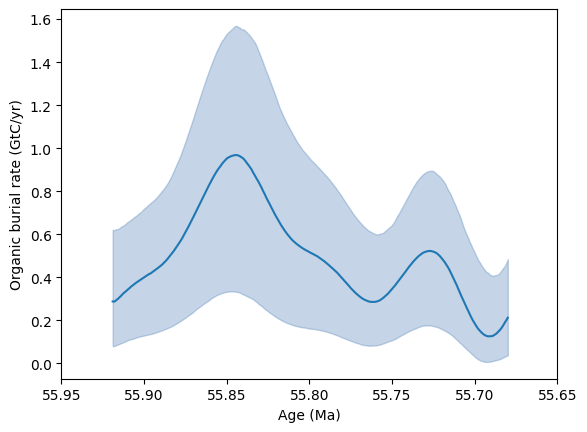

In [37]:
figure,axes = pyplot.subplots(1,1)

burial_per_year_upper = numpy.percentile(organic_carbon_burial_per_year,97.5,axis=0)
burial_per_year_median = numpy.median(organic_carbon_burial_per_year,axis=0)
burial_per_year_lower = numpy.percentile(organic_carbon_burial_per_year,2.5,axis=0)

axes.fill_between(time[1:],burial_per_year_upper,burial_per_year_lower,color="#4276b1",alpha=0.3)

axes.plot(time[1:],burial_per_year_median)

axes.set_xlabel("Age (Ma)")
axes.set_ylabel("Organic burial rate (GtC/yr)")

axes.set_xlim((55.95,55.65))


a = 5